# Q4 - SVD of the original model

Use the original `meta-llama/Llama-3.2-1B` weights. For `q_proj` in layers
0, 7 and 15, find the smallest rank that keeps at least 50% of the energy.
Plot cumulative energy and singular values for the first 200 components.

On Kaggle, enable Internet, a GPU and the `HF_TOKEN` secret, then run all cells.
Results go to `/kaggle/working/Assignment1_Q4`. No training is needed here.


In [1]:
import gc
import json
import os
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import Markdown, display
from transformers import AutoModelForCausalLM

MODEL_ID = 'meta-llama/Llama-3.2-1B'
LAYER_INDICES = [0, 7, 15]
ENERGY_THRESHOLD = 0.50
PLOT_LIMIT = 200
IS_KAGGLE = os.name != 'nt' and Path('/kaggle/working').exists()
RESULT_ROOT = (Path('/kaggle/working/Assignment1_Q4')
               if IS_KAGGLE
               else Path('output/q4'))
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
SVD_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
PROGRESS_LOG = RESULT_ROOT / 'run_progress.log'
PROGRESS_LOG.write_text('', encoding='utf-8')

def log_progress(message):
    line = f'[{time.strftime("%Y-%m-%d %H:%M:%S")}] {message}'
    print(line, flush=True)
    with PROGRESS_LOG.open('a', encoding='utf-8') as stream:
        stream.write(line + '\n')

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 11,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'savefig.dpi': 300,
})
log_progress(f'CONFIG | model={MODEL_ID} | layers={LAYER_INDICES} | SVD device={SVD_DEVICE}')


[2026-10-01 04:33:12] CONFIG | model=meta-llama/Llama-3.2-1B | layers=[0, 7, 15] | SVD device=cuda:0


In [2]:
# Get HF_TOKEN from the environment or Kaggle Secrets.
HF_TOKEN = os.environ.get('HF_TOKEN')
if IS_KAGGLE:
    from kaggle_secrets import UserSecretsClient
    try:
        HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        raise RuntimeError(
            'Enable the Kaggle secret HF_TOKEN for this notebook, then run again. '
            'The token must have access to meta-llama/Llama-3.2-1B.'
        ) from None

log_progress('MODEL LOAD START | original pretrained weights, FP32, CPU')
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.float32,
    low_cpu_mem_usage=True, token=HF_TOKEN,
)
model.eval()
model.requires_grad_(False)
assert max(LAYER_INDICES) < len(model.model.layers)
MODEL_REVISION = getattr(model.config, '_commit_hash', None)
log_progress(f'MODEL LOAD COMPLETE | revision={MODEL_REVISION}')


[2026-10-01 04:33:12] MODEL LOAD START | original pretrained weights, FP32, CPU


config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.47G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

[2026-10-01 04:33:34] MODEL LOAD COMPLETE | revision=4e20de362430cd3b72f300e6b0f18e50e7166e08


## Energy calculation

$E(r)=\sum_{i=1}^{r}\sigma_i^2 / \sum_{i=1}^{k}\sigma_i^2$

Use the full spectrum for the denominator and find the first rank where
$E(r)\geq 0.5$. The plots only show the first 200 values. Indices start at 1.

Load weights in FP32, then do SVD and energy sums in FP64.
On CUDA, use `gesvd`. Check the total squared singular values against the
matrix's Frobenius energy before using the result.


In [3]:
@torch.no_grad()
def analyze_q_projection(weight, layer_index, device):
    if weight.ndim != 2 or not torch.isfinite(weight).all().item():
        raise ValueError(f'Layer {layer_index}: expected a finite weight matrix.')
    if not 0 < ENERGY_THRESHOLD <= 1:
        raise ValueError('ENERGY_THRESHOLD must be in (0, 1].')
    matrix = weight.detach().to(device=device, dtype=torch.float64)
    start = time.perf_counter()
    driver_options = {'driver': 'gesvd'} if matrix.is_cuda else {}
    U, S, Vh = torch.linalg.svd(matrix, full_matrices=False, **driver_options)
    singular_values = S.detach().cpu().double()
    weight_energy = matrix.double().square().sum().item()
    del U, S, Vh, matrix
    seconds = time.perf_counter() - start

    assert len(singular_values) == min(weight.shape)
    assert torch.isfinite(singular_values).all().item()
    assert (singular_values >= 0).all().item()
    assert (singular_values[:-1] >= singular_values[1:]).all().item()
    squared = singular_values.square()
    total_energy = squared.sum()
    if total_energy.item() <= 0:
        raise ValueError(f'Layer {layer_index}: zero-energy matrix.')
    energy_relative_error = abs(total_energy.item() - weight_energy) / weight_energy
    assert np.isclose(total_energy.item(), weight_energy, rtol=1e-5), (
        f'Layer {layer_index}: SVD energy relative error={energy_relative_error:.3e}'
    )
    cumulative = squared.cumsum(dim=0) / total_energy
    assert (cumulative[1:] >= cumulative[:-1]).all().item()
    assert np.isclose(cumulative[-1].item(), 1.0, atol=1e-10)
    rank = int(torch.searchsorted(cumulative, ENERGY_THRESHOLD, right=False).item()) + 1
    energy_at_rank = cumulative[rank - 1].item()
    energy_before_rank = cumulative[rank - 2].item() if rank > 1 else 0.0
    assert energy_before_rank < ENERGY_THRESHOLD <= energy_at_rank

    spectrum = pd.DataFrame({
        'layer': layer_index,
        'singular_value_index': np.arange(1, len(singular_values) + 1),
        'singular_value': singular_values.numpy(),
        'component_energy_pct': (100 * squared / total_energy).numpy(),
        'cumulative_energy_pct': (100 * cumulative).numpy(),
    })
    summary = {
        'layer': layer_index, 'weight_shape': list(weight.shape),
        'singular_value_count': len(singular_values),
        'minimum_rank_50pct': rank,
        'energy_before_rank_pct': 100 * energy_before_rank,
        'energy_at_rank_pct': 100 * energy_at_rank,
        'top16_energy_pct': 100 * cumulative[min(16, len(cumulative)) - 1].item(),
        'top200_energy_pct': 100 * cumulative[min(PLOT_LIMIT, len(cumulative)) - 1].item(),
        'total_squared_energy': total_energy.item(), 'svd_seconds': seconds,
        'energy_relative_error': energy_relative_error,
    }
    return spectrum, summary

spectra, summaries = {}, []
for layer_index in LAYER_INDICES:
    log_progress(f'SVD START | layer={layer_index}')
    weight = model.model.layers[layer_index].self_attn.q_proj.weight
    spectrum, summary = analyze_q_projection(weight, layer_index, SVD_DEVICE)
    spectra[layer_index] = spectrum
    summaries.append(summary)
    spectrum.to_csv(RESULT_ROOT / f'layer_{layer_index}_q_proj_spectrum.csv', index=False)
    log_progress(
        f'SVD COMPLETE | layer={layer_index} | '
        f'rank50={summary["minimum_rank_50pct"]} | seconds={summary["svd_seconds"]:.2f}'
    )

summary_df = pd.DataFrame(summaries)
summary_df.to_csv(RESULT_ROOT / 'q4_summary.csv', index=False)
(RESULT_ROOT / 'q4_summary.json').write_text(json.dumps(summaries, indent=2), encoding='utf-8')
display(summary_df[[
    'layer', 'minimum_rank_50pct', 'energy_before_rank_pct',
    'energy_at_rank_pct', 'top16_energy_pct', 'top200_energy_pct',
]].round(4))
del weight, model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


[2026-10-01 04:33:34] SVD START | layer=0
[2026-10-01 04:33:38] SVD COMPLETE | layer=0 | rank50=62 | seconds=3.10
[2026-10-01 04:33:38] SVD START | layer=7
[2026-10-01 04:33:40] SVD COMPLETE | layer=7 | rank50=120 | seconds=2.43
[2026-10-01 04:33:40] SVD START | layer=15
[2026-10-01 04:33:43] SVD COMPLETE | layer=15 | rank50=84 | seconds=2.39


,layer,minimum_rank_50pct,energy_before_rank_pct,energy_at_rank_pct,top16_energy_pct,top200_energy_pct
0,0,62,49.9332,50.1701,34.7675,71.2398
1,7,120,49.9926,50.2010,15.3864,63.5434
2,15,84,49.8709,50.1154,20.9538,68.8382


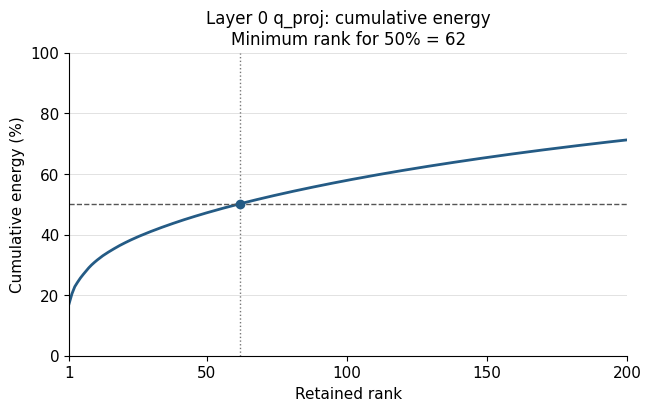

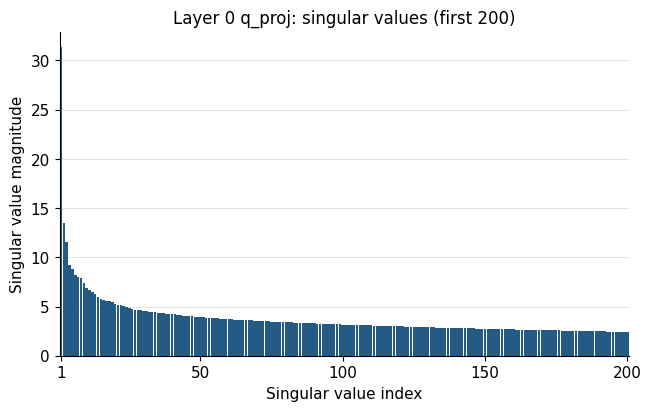

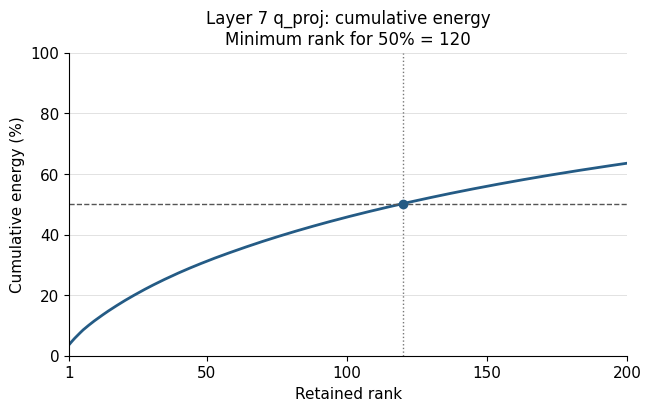

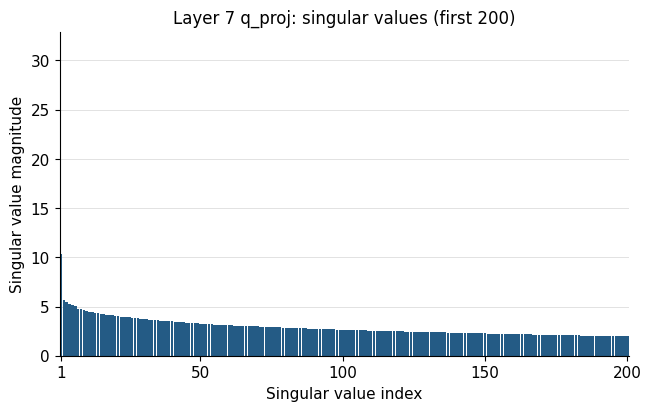

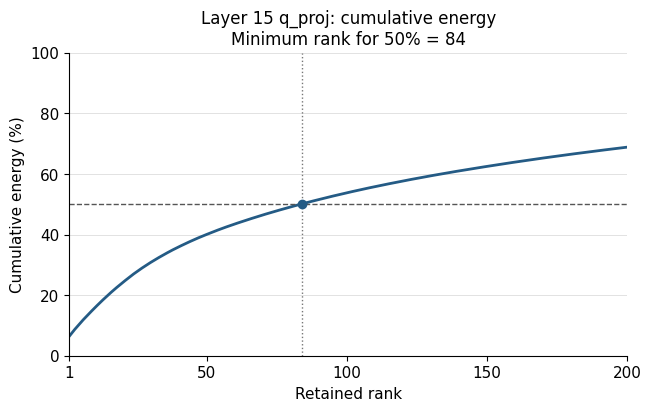

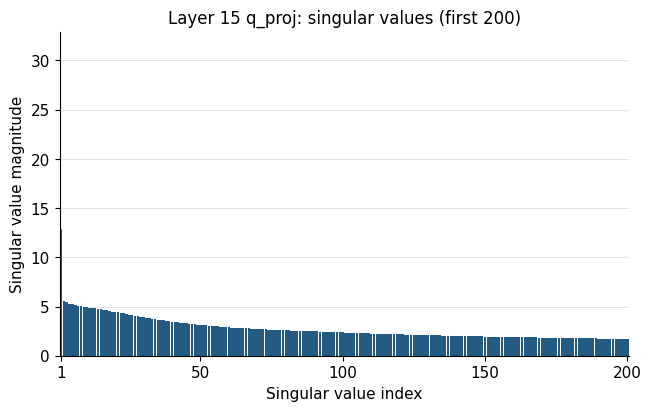

[2026-10-01 04:33:47] CHARTS COMPLETE | six PNG figures saved at 300 dpi


In [4]:
def plot_layer_spectrum(spectrum, summary, output_dir, magnitude_max):
    layer = summary['layer']
    visible = spectrum.iloc[:PLOT_LIMIT]
    x = visible['singular_value_index'].to_numpy()
    rank = summary['minimum_rank_50pct']
    paths = []
    ticks = sorted(set([1] + list(range(50, len(visible) + 1, 50)) + [len(visible)]))

    fig, ax = plt.subplots(figsize=(6.4, 4.0), layout='constrained')
    ax.plot(x, visible['cumulative_energy_pct'], color='#245B85', linewidth=2)
    ax.axhline(ENERGY_THRESHOLD * 100, color='#555555', linestyle='--', linewidth=1)
    if rank <= len(visible):
        ax.scatter([rank], [summary['energy_at_rank_pct']], color='#245B85', zorder=3)
        ax.axvline(rank, color='#777777', linestyle=':', linewidth=1)
    ax.set(title=f'Layer {layer} q_proj: cumulative energy\nMinimum rank for 50% = {rank}',
           xlabel='Retained rank', ylabel='Cumulative energy (%)',
           xlim=(1, len(visible)), ylim=(0, 100))
    ax.set_xticks(ticks)
    ax.grid(axis='y', color='#DDDDDD', linewidth=0.6)
    ax.set_axisbelow(True)
    path = output_dir / f'layer_{layer}_cumulative_energy.png'
    fig.savefig(path)
    paths.append(path)
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(6.4, 4.0), layout='constrained')
    ax.bar(x, visible['singular_value'], width=0.9, color='#245B85', linewidth=0)
    ax.set(title=f'Layer {layer} q_proj: singular values (first {len(visible)})',
           xlabel='Singular value index', ylabel='Singular value magnitude',
           xlim=(0.5, len(visible) + 0.5), ylim=(0, magnitude_max))
    ax.set_xticks(ticks)
    ax.grid(axis='y', color='#DDDDDD', linewidth=0.6)
    ax.set_axisbelow(True)
    path = output_dir / f'layer_{layer}_singular_values.png'
    fig.savefig(path)
    paths.append(path)
    plt.show()
    plt.close(fig)
    return paths

# Same scales for all three layers
magnitude_max = max(s['singular_value'].iloc[0] for s in spectra.values()) * 1.05
chart_paths = []
for summary in summaries:
    chart_paths.extend(plot_layer_spectrum(
        spectra[summary['layer']], summary, RESULT_ROOT, magnitude_max,
    ))
assert len(chart_paths) == 6 and all(p.is_file() and p.stat().st_size > 0 for p in chart_paths)
log_progress('CHARTS COMPLETE | six PNG figures saved at 300 dpi')


In [5]:
# Write the measured results to a markdown file
observations = ['# Q4 results', '']
for row in summaries:
    observations.append(
        f'- Layer {row["layer"]}: minimum rank for 50% energy = {row["minimum_rank_50pct"]}. '
        f'Previous rank: {row["energy_before_rank_pct"]:.4f}%; '
        f'chosen rank: {row["energy_at_rank_pct"]:.4f}%. '
        f'Top 16: {row["top16_energy_pct"]:.2f}%; '
        f'top {PLOT_LIMIT}: {row["top200_energy_pct"]:.2f}%.'
    )
ranked = sorted(summaries, key=lambda row: row['minimum_rank_50pct'])
smallest = ranked[0]['minimum_rank_50pct']
largest = ranked[-1]['minimum_rank_50pct']
if smallest != largest:
    low_layers = [r['layer'] for r in ranked if r['minimum_rank_50pct'] == smallest]
    high_layers = [r['layer'] for r in ranked if r['minimum_rank_50pct'] == largest]
    observations.append(
        f'- Layers {low_layers} require the fewest components ({smallest}) to '
        f'retain half the energy; layers {high_layers} require the most ({largest}).'
    )
else:
    observations.append(f'- All three layers need rank {smallest} for half the energy.')
observations += [
    '- A steeper curve means more energy is in the first few components. '
    'Compare energy percentages across layers since weight magnitudes differ.',
    '- These are the original q_proj weights. Keeping 50% of the weight energy '
    'does not tell us the best fine-tuning rank or the model accuracy.',
]
observation_text = '\n'.join(observations) + '\n'
(RESULT_ROOT / 'q4_observations.md').write_text(observation_text, encoding='utf-8')
display(Markdown(observation_text))

metadata = {
    'model_id': MODEL_ID, 'model_revision': MODEL_REVISION,
    'model_source': 'original pretrained Hugging Face model',
    'layers': LAYER_INDICES, 'energy_threshold': ENERGY_THRESHOLD,
    'plot_limit': PLOT_LIMIT, 'weight_dtype': 'float32',
    'svd_dtype': 'float64', 'energy_accumulation_dtype': 'float64',
    'svd_driver': 'gesvd' if SVD_DEVICE.type == 'cuda' else 'default CPU LAPACK',
    'svd_device': str(SVD_DEVICE), 'python_version': platform.python_version(),
    'torch_version': torch.__version__, 'transformers_version': transformers.__version__,
    'gpu_name': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'rank_indexing': 'one-based', 'energy_denominator': 'complete singular-value spectrum',
    'checkpoint_saved': False,
}
(RESULT_ROOT / 'q4_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
expected = [RESULT_ROOT / f'layer_{i}_q_proj_spectrum.csv' for i in LAYER_INDICES]
expected += chart_paths + [RESULT_ROOT / name for name in [
    'q4_summary.csv', 'q4_summary.json', 'q4_metadata.json',
    'q4_observations.md', 'run_progress.log',
]]
assert all(p.is_file() and p.stat().st_size > 0 for p in expected)
log_progress(f'COMPLETE | {len(expected)} analysis files | output={RESULT_ROOT}')
display(pd.DataFrame({'file': [p.name for p in expected],
                      'bytes': [p.stat().st_size for p in expected]}))


# Q4 results

- Layer 0: minimum rank for 50% energy = 62. Previous rank: 49.9332%; chosen rank: 50.1701%. Top 16: 34.77%; top 200: 71.24%.
- Layer 7: minimum rank for 50% energy = 120. Previous rank: 49.9926%; chosen rank: 50.2010%. Top 16: 15.39%; top 200: 63.54%.
- Layer 15: minimum rank for 50% energy = 84. Previous rank: 49.8709%; chosen rank: 50.1154%. Top 16: 20.95%; top 200: 68.84%.
- Layers [0] require the fewest components (62) to retain half the energy; layers [7] require the most (120).
- A steeper curve means more energy is in the first few components. Compare energy percentages across layers since weight magnitudes differ.
- These are the original q_proj weights. Keeping 50% of the weight energy does not tell us the best fine-tuning rank or the model accuracy.


[2026-10-01 04:33:47] COMPLETE | 14 analysis files | output=/kaggle/working/Assignment1_Q4


,file,bytes
0,layer_0_q_proj_spectrum.csv,132437
1,layer_7_q_proj_spectrum.csv,132532
2,layer_15_q_proj_spectrum.csv,134745
3,layer_0_cumulative_energy.png,106032
4,layer_0_singular_values.png,75155
5,layer_7_cumulative_energy.png,108929
6,layer_7_singular_values.png,75130
7,layer_15_cumulative_energy.png,108472
8,layer_15_singular_values.png,75311
9,q4_summary.csv,663
